# Predicción de la posición final de Max Verstappen — Segundo corte

**Proyecto de Inteligencia Artificial: Fórmula 1 (segundo corte)**

Equipo: Iván Moros / Juan Daniel Cuervo

Este notebook implementa lo que se propuso en el primer corte con el dataset público "Formula 1 Race Dataset for Predictive Analysis" (Kaggle). Sigue la estructura pedida para el segundo corte: contexto y continuidad, limpieza y análisis exploratorio, ingeniería y reducción de variables, modelado, resultados y despliegue.

# 1. Contexto y continuidad

## 1.1 Contexto y problema

En la Fórmula 1, el resultado de un piloto puede estar relacionado con factores del piloto, del equipo, del circuito y de la carrera. En el primer corte se planteó estimar la posición final (`FinishPosition`) usando **solamente información disponible antes de la carrera**, es decir, con la parrilla de salida ya definida tras la clasificación.

En este corte se mantiene el mismo dataset y la misma pregunta, enfocada en un piloto: **¿en qué posición va a terminar Max Verstappen una carrera si solo usamos lo que se sabe antes de que empiece** (año, circuito, clima pronosticado, posición de clasificación y posición de salida)?

- **Tipo de aprendizaje:** supervisado (predictivo). Se conoce la posición final de cada carrera del dataset y se quiere estimarla para carreras nuevas.
- **Tipo de problema:** regresión. La posición es un número de 1 a 20 (menor = mejor) y el error se mide en posiciones.
- **Momento de predicción:** con la parrilla ya definida (después de la clasificación) y antes de la carrera.

## 1.2 Cambios respecto al primer corte

El problema no cambia (estimar la posición final de un piloto antes de la carrera). Los cambios son refinamientos y cada uno se comprueba con código más abajo.

| Decisión | Primer corte | Segundo corte | Justificación (evidencia) |
|---|---|---|---|
| Pilotos | Los 20 pilotos (6.000 registros) | Solo Max Verstappen (300 registros) | En el primer corte las variables de piloto y equipo aportaron poco y el modelo daba resultados casi iguales para todos. Con un solo piloto la pregunta es más concreta. Sección 2.1 |
| `Driver` y `Team` | Predictoras | Se excluyen | Con un solo piloto son constantes: 1 piloto y 1 equipo (`Red Bull Racing`) en las 300 filas. Sección 2.1 |
| Abandonos (`DNF = 1`) | No se quitaba ninguna fila (613 DNF) | Se quitan 20 filas (300 → 280) | Su posición final no es una llegada real: 5 de los 20 abandonos de Verstappen figuran con posición final 1. `DNF` sigue fuera de X (Data Leakage). Sección 2.2 |
| División de los datos | `GroupShuffleSplit` + `GroupKFold` por carrera | `train_test_split` 80/20 + `KFold(n_splits=5, shuffle=True, random_state=42)` | Antes cada carrera tenía 20 filas y había que mantenerlas juntas. Ahora hay 300 `RaceID` distintos para 300 filas (1 fila por carrera), así que ninguna carrera puede quedar partida. Secciones 2.1 y 3.2 |
| Escalamiento | No se aplicaba | Solo en la rama con PCA | PCA es sensible a la escala y necesita `StandardScaler`. Los modelos sin PCA siguen sin escalar, como en el primer corte. Sección 3.3 |
| Reducción de variables | No había | PCA (con y sin PCA) | Lo pide el segundo corte. Se justifica por la correlación de 0.94 entre `StartPosition` y `QualifyingPosition` y por las 37 columnas para 224 filas de entrenamiento. Sección 3.3 |
| Métricas | MAE, RMSE y R² | MAE, MSE, RMSE y R² | Se agrega MSE, que pide el segundo corte. Sección 4 |
| Parámetros de los modelos | Fijos, sin ajustar (trabajo futuro) | Se ajustan con `GridSearchCV` | Responde a la limitación que quedó en el primer corte. Sección 4.4 |
| Elección del mejor modelo | Por resultado en prueba | Por validación cruzada | El conjunto de prueba se usa una sola vez; elegir con él sería ajustar decisiones a una sola división. Sección 5.4 |

## 1.3 Resultados esperados

- Superar con claridad a la referencia "Predecir el promedio (entrenamiento)", que no usa ninguna información de la carrera.
- Compararse con la referencia "Usar StartPosition" (predecir que Verstappen termina donde salió). En el primer corte los modelos quedaron muy cerca de esta regla, así que se espera algo parecido.
- Medir si PCA ayuda o no, y si ajustar los parámetros mejora a los árboles.

## 1.4 Carga de datos

Se importan las librerías básicas y se carga el archivo `f1_enhanced_dataset_for_analysis.csv` directamente desde Kaggle con `kagglehub`, igual que en el primer corte.

- Dataset: [Formula 1 Race Dataset for Predictive Analysis](https://www.kaggle.com/datasets/usman136/formula-1-race-dataset-for-predictive-analysis)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [2]:
!pip install -q "kagglehub[pandas-datasets]"

In [3]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Descarga y carga del archivo CSV en un DataFrame
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "usman136/formula-1-race-dataset-for-predictive-analysis",
    "f1_enhanced_dataset_for_analysis.csv"
)

df.head()

,RaceID,Year,RaceName,Location,Weather,Driver,Team,StartPosition,FinishPosition,FastestLapTime_sec,DNF,Points,PitStopCount,QualifyingPosition,TireStrategy,Overtakes,RaceTime_sec
0,1,2014,GP_1,Country_23,Rainy,Max Verstappen,Red Bull Racing,2,2,97.884,0,24,3,4,Two-stop,0,5652.69
1,1,2014,GP_1,Country_23,Rainy,Sergio Perez,Red Bull Racing,5,1,97.726,0,25,2,6,Soft-Hard,4,5693.52
2,1,2014,GP_1,Country_23,Rainy,Lewis Hamilton,Mercedes,11,10,89.997,0,16,4,10,Medium-Hard,1,5237.08
3,1,2014,GP_1,Country_23,Rainy,George Russell,Mercedes,15,18,100.776,0,8,3,16,Two-stop,0,5811.35
4,1,2014,GP_1,Country_23,Rainy,Charles Leclerc,Ferrari,3,2,97.040,0,24,3,1,Two-stop,1,5679.57


In [4]:
# Número de filas y columnas del dataset completo (primer corte: 6.000 filas y 17 columnas)
print("Filas y columnas del dataset completo:", df.shape)

Filas y columnas del dataset completo: (6000, 17)


# 2. Limpieza y análisis exploratorio

## 2.1 Filtrado del piloto

In [5]:
# Registros de Max Verstappen
df_verstappen = df[df['Driver'] == 'Max Verstappen'].copy()

print("Registros de Max Verstappen:", len(df_verstappen))
print("Carreras distintas:", df_verstappen['RaceID'].nunique())

# Filas por carrera (1 = una sola fila por carrera)
print("Filas por carrera:", df_verstappen.groupby('RaceID').size().unique())

# Pilotos y equipos distintos en el subconjunto (1 = la columna es constante)
print("Pilotos distintos:", df_verstappen['Driver'].nunique())
print("Equipos distintos:", df_verstappen['Team'].nunique(), df_verstappen['Team'].unique())

Registros de Max Verstappen: 300
Carreras distintas: 300
Filas por carrera: [1]
Pilotos distintos: 1
Equipos distintos: 1 <ArrowStringArray>
['Red Bull Racing']
Length: 1, dtype: str


### Interpretación

Max Verstappen tiene 300 registros, uno por carrera (300 `RaceID` distintos y 1 fila por carrera). `Driver` y `Team` tienen un solo valor (`Red Bull Racing`), así que no pueden ayudar a predecir y se excluyen en la Sección 2.3. Como hay una fila por carrera, ya no hace falta dividir por grupos como en el primer corte.

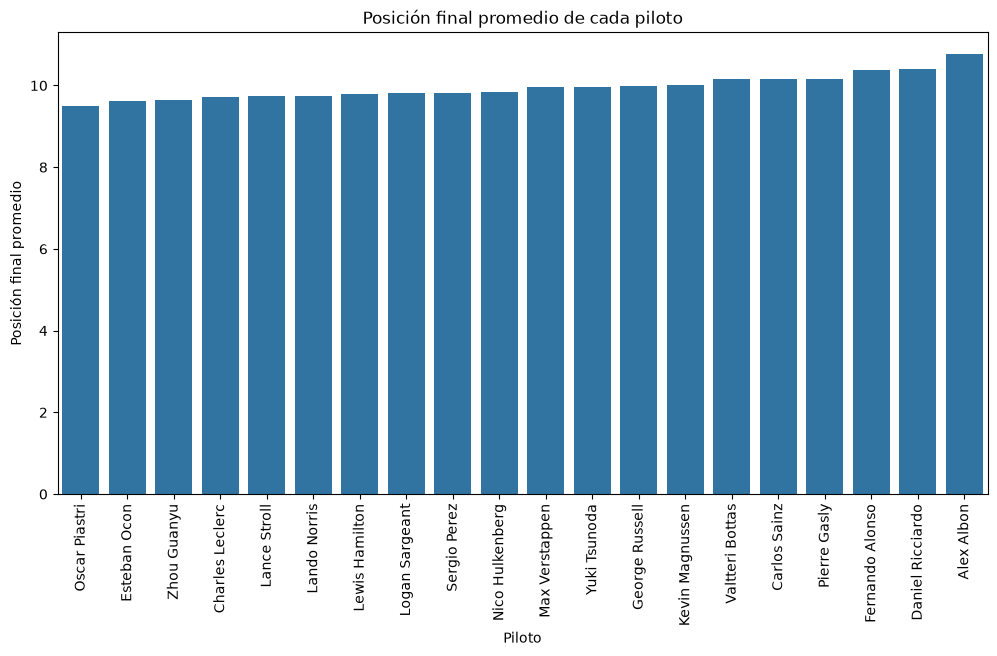

In [6]:
# Posición final promedio de cada piloto (los 20 pilotos, sin abandonos)
promedio_pilotos = df[df['DNF'] == 0].groupby('Driver')['FinishPosition'].mean().sort_values()

plt.figure(figsize=(12, 6))

sns.barplot(x=promedio_pilotos.index, y=promedio_pilotos.values)

plt.title('Posición final promedio de cada piloto')
plt.xlabel('Piloto')
plt.ylabel('Posición final promedio')
plt.xticks(rotation=90)

plt.show()

In [7]:
# Posición promedio de Verstappen frente al resto de pilotos
print("Posición final promedio de Max Verstappen:", round(promedio_pilotos['Max Verstappen'], 2))
print("Promedio más bajo (mejor):", round(promedio_pilotos.min(), 2), "-", promedio_pilotos.idxmin())
print("Promedio más alto (peor):", round(promedio_pilotos.max(), 2), "-", promedio_pilotos.idxmax())

Posición final promedio de Max Verstappen: 9.96
Promedio más bajo (mejor): 9.5 - Oscar Piastri
Promedio más alto (peor): 10.77 - Alex Albon


### Interpretación

Las posiciones finales promedio de los 20 pilotos están entre 9.5 (Oscar Piastri) y 10.77 (Alex Albon); Verstappen tiene 9.96, casi el promedio general. En la F1 real Verstappen gana muchas más carreras que el resto, así que esto confirma lo que se vio en el primer corte: el dataset parece sintético o simulado y los resultados valen para este dataset, no para la Fórmula 1 real.

## 2.2 Limpieza

Se aplican los seis tratamientos que pide el segundo corte, en el orden visto en clase (tipos → formatos → duplicados → errores → nulos → outliers), y al final el tratamiento de los abandonos. En cada paso se detecta el problema, se decide qué hacer y se reporta cuántas filas o columnas se afectan.

In [8]:
# 1) Tipos de datos
df_verstappen.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 5980
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RaceID              300 non-null    int64  
 1   Year                300 non-null    int64  
 2   RaceName            300 non-null    str    
 3   Location            300 non-null    str    
 4   Weather             300 non-null    str    
 5   Driver              300 non-null    str    
 6   Team                300 non-null    str    
 7   StartPosition       300 non-null    int64  
 8   FinishPosition      300 non-null    int64  
 9   FastestLapTime_sec  300 non-null    float64
 10  DNF                 300 non-null    int64  
 11  Points              300 non-null    int64  
 12  PitStopCount        300 non-null    int64  
 13  QualifyingPosition  300 non-null    int64  
 14  TireStrategy        300 non-null    str    
 15  Overtakes           300 non-null    int64  
 16  RaceTime_sec      

In [9]:
# Conversión a número de las columnas que deben ser numéricas
# errors='coerce' deja NaN si algún valor no es un número (así se detectaría un tipo incorrecto)
columnas_enteras = ['Year', 'StartPosition', 'QualifyingPosition', 'FinishPosition', 'DNF', 'Points']

for columna in columnas_enteras:
    convertida = pd.to_numeric(df_verstappen[columna], errors='coerce')
    print(f"{columna}: tipo = {df_verstappen[columna].dtype}, valores no numéricos = {convertida.isnull().sum()}")
    df_verstappen[columna] = convertida

Year: tipo = int64, valores no numéricos = 0
StartPosition: tipo = int64, valores no numéricos = 0
QualifyingPosition: tipo = int64, valores no numéricos = 0
FinishPosition: tipo = int64, valores no numéricos = 0
DNF: tipo = int64, valores no numéricos = 0
Points: tipo = int64, valores no numéricos = 0


In [10]:
# 2) Formatos inconsistentes en las variables de texto
print("Valores de Weather:", df_verstappen['Weather'].unique())

for columna in ['Location', 'Weather', 'Team']:
    categorias = df_verstappen[columna].nunique()
    categorias_normalizadas = df_verstappen[columna].str.lower().str.strip().nunique()
    con_espacios = (df_verstappen[columna] != df_verstappen[columna].str.strip()).sum()
    print(f"{columna}: categorías = {categorias}, sin mayúsculas ni espacios = {categorias_normalizadas}, "
          f"valores con espacios = {con_espacios}")

# Se quitan los espacios sobrantes (si los valores ya están bien escritos no cambia nada)
for columna in ['Location', 'Weather']:
    df_verstappen[columna] = df_verstappen[columna].str.strip()

Valores de Weather: <ArrowStringArray>
['Rainy', 'Sunny', 'Windy', 'Cloudy']
Length: 4, dtype: str
Location: categorías = 30, sin mayúsculas ni espacios = 30, valores con espacios = 0
Weather: categorías = 4, sin mayúsculas ni espacios = 4, valores con espacios = 0
Team: categorías = 1, sin mayúsculas ni espacios = 1, valores con espacios = 0


In [11]:
# 3) Registros duplicados
print("Registros duplicados:", df_verstappen.duplicated().sum())
print("Carreras repetidas (mismo RaceID):", df_verstappen.duplicated(subset='RaceID').sum())

df_verstappen = df_verstappen.drop_duplicates()
print("Registros después de quitar duplicados:", len(df_verstappen))

Registros duplicados: 0
Carreras repetidas (mismo RaceID): 0
Registros después de quitar duplicados: 300


In [12]:
# 4) Errores de digitación: mínimos y máximos de las variables numéricas
for columna in ['Year', 'StartPosition', 'QualifyingPosition', 'FinishPosition', 'DNF']:
    print(f"{columna}: mínimo = {df_verstappen[columna].min()}, máximo = {df_verstappen[columna].max()}")

Year: mínimo = 2010, máximo = 2024
StartPosition: mínimo = 1, máximo = 20
QualifyingPosition: mínimo = 1, máximo = 20
FinishPosition: mínimo = 1, máximo = 20
DNF: mínimo = 0, máximo = 1


In [13]:
# Rangos válidos: posiciones de 1 a 20, años desde 1950 (primera temporada de F1) y DNF solo 0 o 1
fuera_de_rango = df_verstappen[
    (df_verstappen['StartPosition'] < 1) | (df_verstappen['StartPosition'] > 20) |
    (df_verstappen['QualifyingPosition'] < 1) | (df_verstappen['QualifyingPosition'] > 20) |
    (df_verstappen['FinishPosition'] < 1) | (df_verstappen['FinishPosition'] > 20) |
    (df_verstappen['Year'] < 1950) | (df_verstappen['Year'] > 2024) |
    (~df_verstappen['DNF'].isin([0, 1]))
]

print("Registros con valores fuera de rango:", len(fuera_de_rango))

Registros con valores fuera de rango: 0


In [14]:
# 5) Valores nulos por columna
print("Valores nulos en total:", df_verstappen.isnull().sum().sum())

df_verstappen.isnull().sum()

Valores nulos en total: 0


RaceID                0
Year                  0
RaceName              0
Location              0
Weather               0
Driver                0
Team                  0
StartPosition         0
FinishPosition        0
FastestLapTime_sec    0
DNF                   0
Points                0
PitStopCount          0
QualifyingPosition    0
TireStrategy          0
Overtakes             0
RaceTime_sec          0
dtype: int64

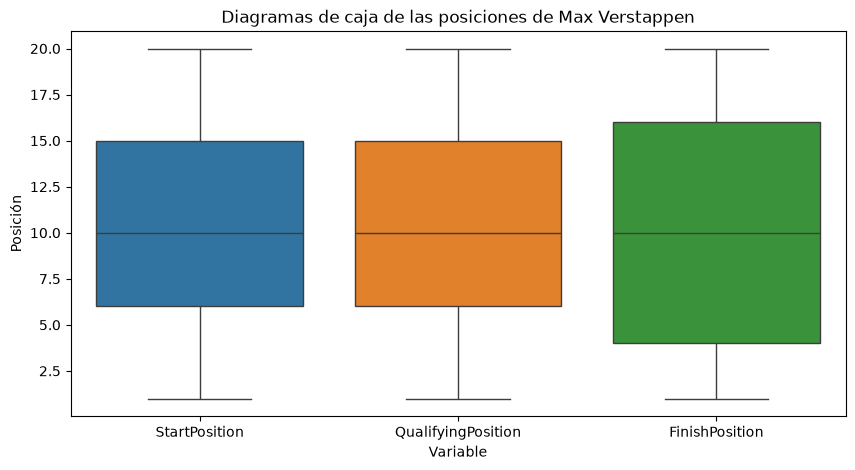

In [15]:
# 6) Outliers: diagramas de caja de las posiciones
plt.figure(figsize=(10, 5))

sns.boxplot(data=df_verstappen[['StartPosition', 'QualifyingPosition', 'FinishPosition']])

plt.title('Diagramas de caja de las posiciones de Max Verstappen')
plt.xlabel('Variable')
plt.ylabel('Posición')

plt.show()

In [16]:
# Outliers con el método IQR (rango intercuartílico)
for columna in ['Year', 'StartPosition', 'QualifyingPosition', 'FinishPosition']:
    Q1 = df_verstappen[columna].quantile(0.25)
    Q3 = df_verstappen[columna].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_verstappen[(df_verstappen[columna] < lower_bound) | (df_verstappen[columna] > upper_bound)]
    print(f"{columna}: límites = [{lower_bound}, {upper_bound}], outliers = {len(outliers)}")

Year: límites = [2002.5, 2030.5], outliers = 0


StartPosition: límites = [-7.5, 28.5], outliers = 0
QualifyingPosition: límites = [-7.5, 28.5], outliers = 0
FinishPosition: límites = [-14.0, 34.0], outliers = 0


In [17]:
# 7) Abandonos (DNF): posición final de las carreras que Verstappen no terminó
print("Registros con DNF = 1:", (df_verstappen['DNF'] == 1).sum())

print("\nFinishPosition de los registros con DNF = 1:")
print(df_verstappen.loc[df_verstappen['DNF'] == 1, 'FinishPosition'].value_counts().sort_index())

Registros con DNF = 1: 20

FinishPosition de los registros con DNF = 1:
FinishPosition
1     5
4     2
7     2
8     1
9     1
10    1
11    1
12    1
13    1
14    1
17    2
18    1
20    1
Name: count, dtype: int64


In [18]:
# Se quitan los abandonos: su posición final no es una llegada real
df_limpio = df_verstappen[df_verstappen['DNF'] == 0].copy()

print("Filas eliminadas por DNF:", len(df_verstappen) - len(df_limpio))
print("Filas después de la limpieza:", len(df_limpio))

Filas eliminadas por DNF: 20
Filas después de la limpieza: 280


### Interpretación

| Tratamiento | Primer corte (6.000 filas, 17 columnas) | Segundo corte (300 filas de Verstappen) | Filas afectadas | Decisión |
|---|---|---|---|---|
| Tipos de datos | 11 numéricas y 6 categóricas | 9 enteras, 2 decimales y 6 de texto; 0 valores no numéricos | 0 | Se dejan los tipos (ya son correctos) |
| Formatos inconsistentes | No se revisó | `Location` 30 y `Weather` 4 categorías, iguales al pasar a minúsculas; 0 valores con espacios | 0 | `str.strip()` por seguridad, sin cambios |
| Duplicados | 0 | 0 registros duplicados y 0 `RaceID` repetidos | 0 | No se elimina nada |
| Errores de digitación | Rangos revisados: posiciones 1-20 y años 2010-2024 | 0 valores fuera de rango (posiciones 1-20, años desde 1950, `DNF` 0/1) | 0 | No se corrige nada |
| Valores nulos | 0 | 0 | 0 | No se imputa (si hubiera, se usaría mediana o moda) |
| Outliers (IQR) | No se revisó | 0 outliers en `Year`, `StartPosition`, `QualifyingPosition` y `FinishPosition` | 0 | No se recorta: las posiciones 1 y 20 son valores posibles |
| Abandonos (`DNF = 1`) | 613 registros (10.2 %), no se quitaron | 20 registros (6.7 %); 5 de ellos con posición final 1 | **20** | Se eliminan: 300 → 280 filas |

Los datos ya venían limpios en tipos, formatos, duplicados, rangos, nulos y outliers. El único tratamiento que cambia los datos es quitar los abandonos, porque su posición final no representa una llegada real (por ejemplo, 5 abandonos aparecen como si Verstappen hubiera ganado).

## 2.3 Variables para el modelado (Data Leakage)

Se mantiene la tabla del primer corte. Lo único nuevo es que `Driver` y `Team` salen por ser constantes.

| Variable | Momento en que se conoce | Clasificación | Decisión |
|---|---|---|---|
| `Year`, `Location` | Antes de la carrera | Segura | Usar |
| `QualifyingPosition` | Al terminar la clasificación | Segura | Usar |
| `StartPosition` | Al definirse la parrilla | Segura | Usar |
| `Weather` | Como pronóstico, antes de la carrera | Potencialmente problemática | Usar, asumiendo que es el pronóstico |
| `Driver`, `Team` | Antes de la carrera | Constantes para Verstappen | Excluir |
| `TireStrategy` | La estrategia ejecutada se conoce al final | Potencialmente problemática | Excluir por precaución |
| `Points`, `DNF`, `RaceTime_sec` | Al terminar la carrera | Data Leakage | Excluir |
| `FastestLapTime_sec`, `PitStopCount`, `Overtakes` | Se registran durante la carrera | Data Leakage | Excluir |
| `RaceID`, `RaceName` | Antes de la carrera | Identificadores | Excluir |

In [19]:
# Relación entre Points y FinishPosition en las carreras terminadas
print("¿Points = 26 - FinishPosition cuando DNF = 0?",
      (df_limpio['Points'] == 26 - df_limpio['FinishPosition']).all())

¿Points = 26 - FinishPosition cuando DNF = 0? True


In [20]:
# Se eliminan los identificadores, las variables con Data Leakage y las columnas constantes
columnas_a_eliminar = [
    'RaceID',              # identificador de la carrera
    'RaceName',            # identificador de la carrera (equivale a RaceID)
    'Points',              # Data Leakage
    'DNF',                 # Data Leakage
    'FastestLapTime_sec',  # Data Leakage
    'PitStopCount',        # Data Leakage
    'Overtakes',           # Data Leakage
    'RaceTime_sec',        # Data Leakage
    'TireStrategy',        # exclusión por precaución
    'Driver',              # constante: solo Max Verstappen
    'Team'                 # constante: siempre Red Bull Racing
]

df_modelo = df_limpio.drop(columns=columnas_a_eliminar)

print("Columnas antes:", df_limpio.shape[1], "- columnas después:", df_modelo.shape[1])
print("Variables para el modelado (incluye la variable objetivo):")
print(df_modelo.columns.tolist())

Columnas antes: 17 - columnas después: 6
Variables para el modelado (incluye la variable objetivo):
['Year', 'Location', 'Weather', 'StartPosition', 'FinishPosition', 'QualifyingPosition']


### Interpretación

Igual que en el primer corte, `Points` es exactamente `26 − FinishPosition` en las carreras terminadas: contiene la respuesta y no se puede usar. Después de quitar identificadores, variables con Data Leakage y columnas constantes, se pasa de 17 a 6 columnas: 5 predictoras (`Year`, `Location`, `Weather`, `StartPosition`, `QualifyingPosition`) y la variable objetivo.

## 2.4 Análisis univariado

Se observa la distribución de la variable objetivo y de las categóricas. Una posición numéricamente menor es mejor: la 1 es la mejor y la 20 la peor.

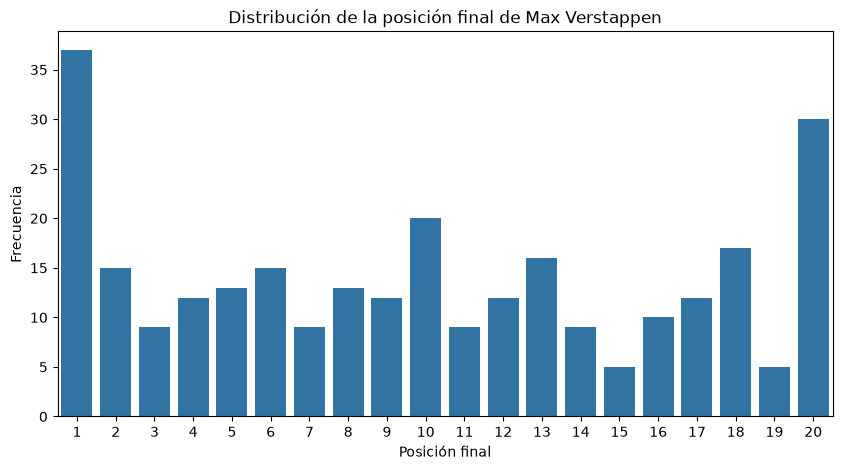

In [21]:
# Distribución de la posición final
plt.figure(figsize=(10, 5))

sns.countplot(data=df_modelo, x='FinishPosition')

plt.title('Distribución de la posición final de Max Verstappen')
plt.xlabel('Posición final')
plt.ylabel('Frecuencia')

plt.show()

In [22]:
# Estadísticas de la posición final
print("Moda:", df_modelo['FinishPosition'].mode()[0])
print("Carreras ganadas (posición 1):", (df_modelo['FinishPosition'] == 1).sum())

df_modelo['FinishPosition'].describe().round(2)

Moda: 1
Carreras ganadas (posición 1): 37


count    280.00
mean       9.96
std        6.41
min        1.00
25%        4.00
50%       10.00
75%       16.00
max       20.00
Name: FinishPosition, dtype: float64

### Interpretación

La posición final de Verstappen cubre todo el rango de 1 a 20, con media 9.96, mediana 10 y desviación estándar 6.41. La posición más frecuente es la 1 (37 victorias en 280 carreras), pero el resto está bastante repartido (la mitad central va de la posición 4 a la 16). Una dispersión tan grande hace que predecir siempre el promedio tenga un error alto, por eso hace falta usar variables de la carrera.

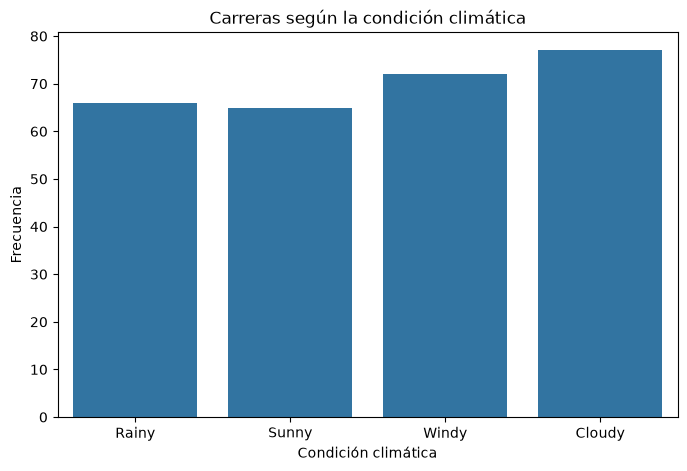

In [23]:
# Carreras según la condición climática
plt.figure(figsize=(8, 5))

sns.countplot(data=df_modelo, x='Weather')

plt.title('Carreras según la condición climática')
plt.xlabel('Condición climática')
plt.ylabel('Frecuencia')

plt.show()

In [24]:
# Frecuencias de las variables categóricas
print("Carreras por clima:")
print(df_modelo['Weather'].value_counts())

conteo_circuitos = df_modelo['Location'].value_counts()
print("\nCircuitos distintos:", df_modelo['Location'].nunique())
print("Carreras por circuito: mínimo =", conteo_circuitos.min(), ", máximo =", conteo_circuitos.max())

Carreras por clima:
Weather
Cloudy    77
Windy     72
Rainy     66
Sunny     65
Name: count, dtype: int64

Circuitos distintos: 30
Carreras por circuito: mínimo = 5 , máximo = 14


### Interpretación

Los cuatro climas están balanceados (entre 65 y 77 carreras). Los 30 circuitos tienen entre 5 y 14 carreras cada uno: son pocas por circuito, así que cualquier diferencia entre circuitos se debe tomar con cuidado.

## 2.5 Análisis bivariado

Se comparan `QualifyingPosition`, `StartPosition`, `Weather`, `Location` y `Year` con `FinishPosition`.

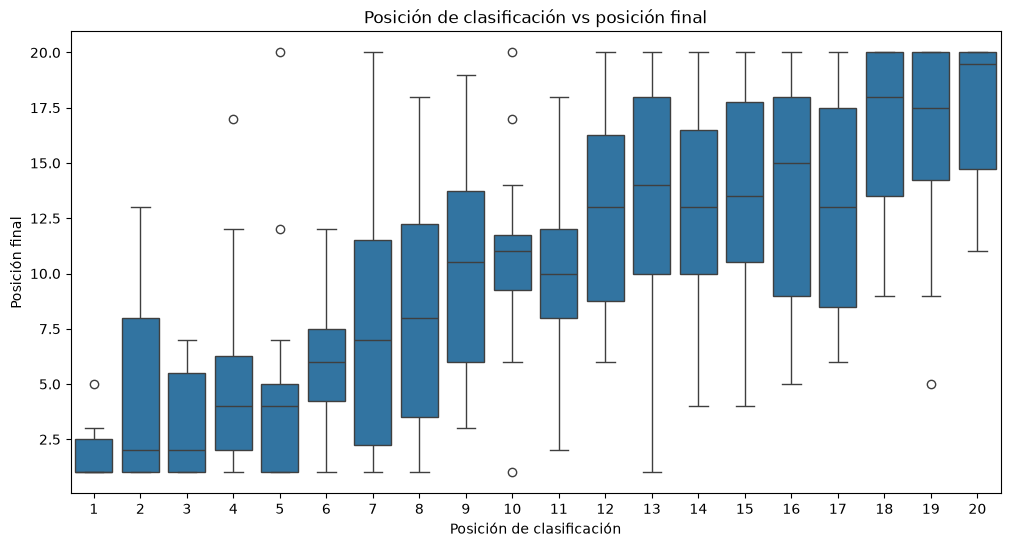

In [25]:
# Posición de clasificación vs posición final
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_modelo, x='QualifyingPosition', y='FinishPosition')

plt.title('Posición de clasificación vs posición final')
plt.xlabel('Posición de clasificación')
plt.ylabel('Posición final')

plt.show()

In [26]:
# Correlación entre QualifyingPosition y FinishPosition
df_modelo[['QualifyingPosition', 'FinishPosition']].corr()

,QualifyingPosition,FinishPosition
QualifyingPosition,1.000000,0.695351
FinishPosition,0.695351,1.000000


### Posición de clasificación vs Posición final

La mediana de la posición final sube cuando empeora la clasificación. La correlación de Pearson es 0.695, una relación lineal positiva relativamente fuerte (asociación, no causalidad). `QualifyingPosition` se conoce antes de la carrera, así que se usa como predictora.

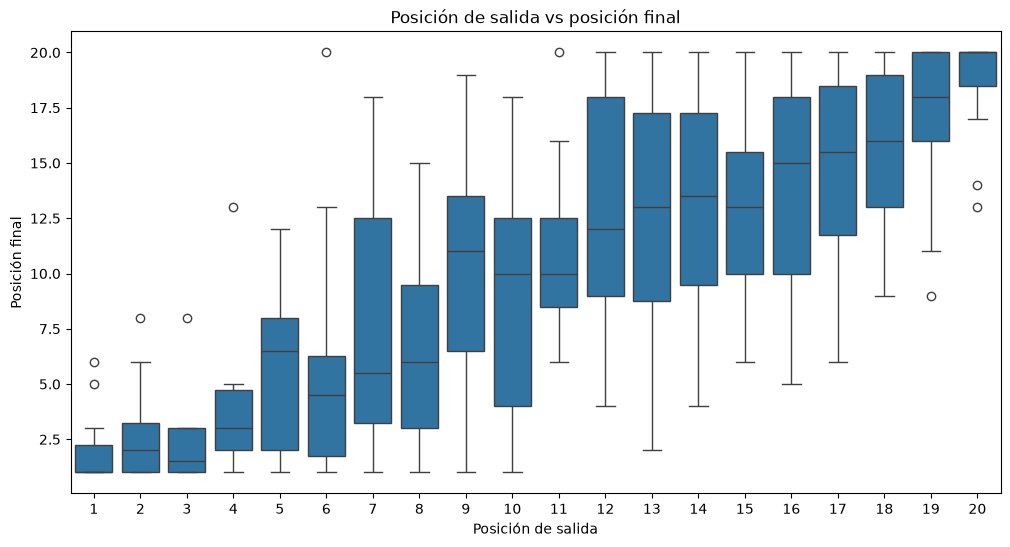

In [27]:
# Posición de salida vs posición final
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_modelo, x='StartPosition', y='FinishPosition')

plt.title('Posición de salida vs posición final')
plt.xlabel('Posición de salida')
plt.ylabel('Posición final')

plt.show()

In [28]:
# Correlación entre StartPosition y FinishPosition
df_modelo[['StartPosition', 'FinishPosition']].corr()

,StartPosition,FinishPosition
StartPosition,1.000000,0.730792
FinishPosition,0.730792,1.000000


In [29]:
# ¿Cuántas posiciones gana o pierde Verstappen respecto a su salida?
diferencia_posiciones = df_modelo['FinishPosition'] - df_modelo['StartPosition']

print("Termina en la misma posición de salida:", (diferencia_posiciones == 0).sum(), "carreras")
print("Diferencia absoluta promedio (salida vs llegada):", round(diferencia_posiciones.abs().mean(), 2))

Termina en la misma posición de salida: 34 carreras
Diferencia absoluta promedio (salida vs llegada): 3.49


### Posición de salida vs Posición final

Es la relación más fuerte: correlación de 0.731 (asociación, no causalidad). Verstappen termina exactamente donde salió en 34 de 280 carreras y, en promedio, termina a 3.49 posiciones de su posición de salida. Esto anticipa que la regla "Usar StartPosition" va a ser una referencia difícil de superar.

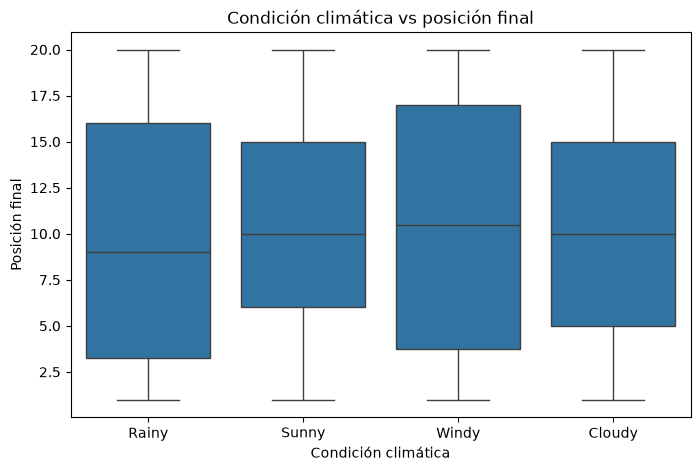

In [30]:
# Condición climática vs posición final
plt.figure(figsize=(8, 5))

sns.boxplot(data=df_modelo, x='Weather', y='FinishPosition')

plt.title('Condición climática vs posición final')
plt.xlabel('Condición climática')
plt.ylabel('Posición final')

plt.show()

In [31]:
# Posición final promedio según la condición climática
df_modelo.groupby('Weather')['FinishPosition'].mean().round(2)

Weather
Cloudy     9.99
Rainy      9.45
Sunny     10.37
Windy     10.03
Name: FinishPosition, dtype: float64

### Condición climática vs Posición final

Las cajas son parecidas. El promedio va de 9.45 (Rainy) a 10.37 (Sunny), una diferencia menor a una posición frente a una desviación estándar de 6.41. El clima aporta poco, pero se mantiene porque se conoce antes de la carrera (como pronóstico) y no genera Data Leakage.

In [32]:
# Posición final promedio por circuito (cada circuito tiene pocas carreras)
promedio_circuito = df_modelo.groupby('Location')['FinishPosition'].mean()

print("Mejor circuito:", promedio_circuito.idxmin(), "-", round(promedio_circuito.min(), 2))
print("Peor circuito:", promedio_circuito.idxmax(), "-", round(promedio_circuito.max(), 2))

Mejor circuito: Country_11 - 5.6
Peor circuito: Country_8 - 12.33


In [33]:
# Posición final promedio por año
df_modelo.groupby('Year')['FinishPosition'].mean().round(2)

Year
2010     9.17
2011     8.76
2012     9.60
2013     8.84
2014     9.32
2015    12.88
2016    10.50
2017    11.42
2018     7.72
2019     8.41
2020    10.83
2021    11.64
2022     9.42
2023    11.44
2024    10.67
Name: FinishPosition, dtype: float64

### Circuito y año vs Posición final

Por circuito, el promedio va de 5.6 (`Country_11`) a 12.33 (`Country_8`), pero cada circuito tiene entre 5 y 14 carreras, así que esas diferencias pueden ser casualidad. Por año, el promedio sube y baja sin tendencia (de 7.72 en 2018 a 12.88 en 2015). Ninguna de las dos variables muestra un patrón claro; se dejan como predictoras para respetar el planteamiento del primer corte, y los modelos dirán si aportan.

## 2.6 Análisis multivariado

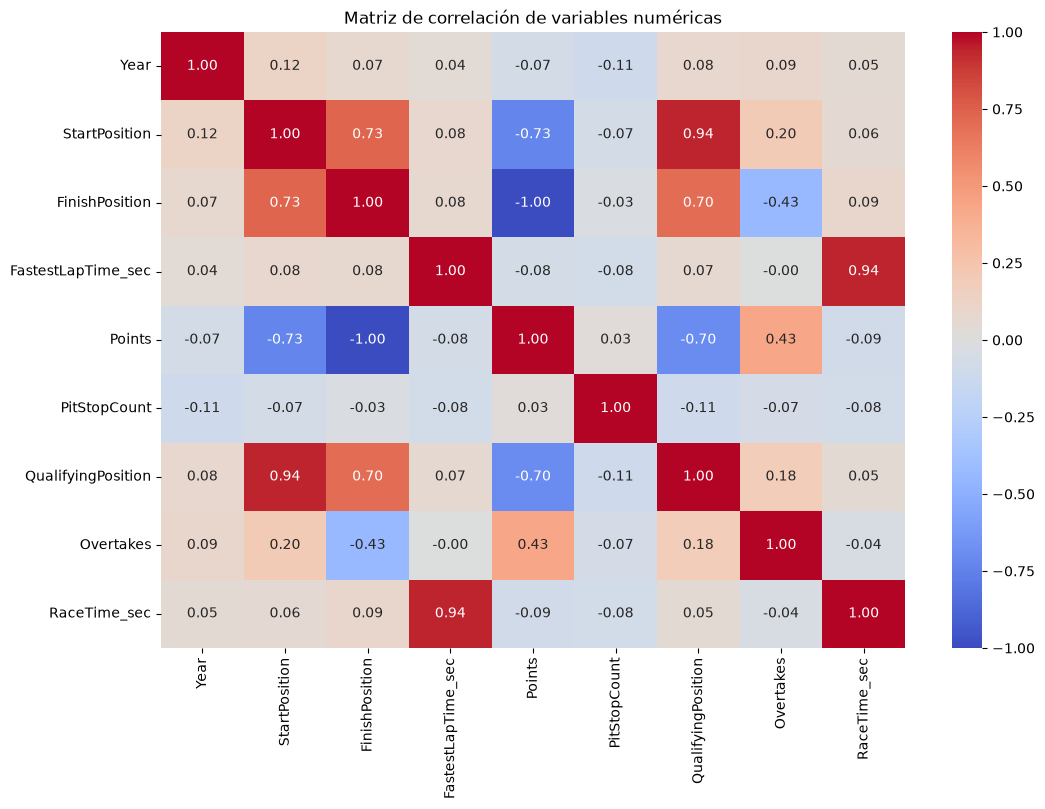

In [34]:
# Matriz de correlación de las variables numéricas (sin RaceID ni DNF, que ya es constante)
correlaciones = df_limpio.select_dtypes(include=np.number).drop(columns=['RaceID', 'DNF']).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)

plt.title('Matriz de correlación de variables numéricas')

plt.show()

### Interpretación

- `StartPosition` (0.73) y `QualifyingPosition` (0.70) son las variables previas a la carrera con más relación con `FinishPosition`. `Year` casi no tiene relación lineal (0.07).
- `StartPosition` y `QualifyingPosition` tienen correlación de 0.94 entre sí: contienen casi la misma información (multicolinealidad). Esto justifica probar PCA en la Sección 3.
- `Points` tiene correlación de −1.00 con `FinishPosition` y `Overtakes` −0.43, pero ambas son posteriores a la carrera (Data Leakage) y no se usan.
- `FastestLapTime_sec` y `RaceTime_sec` tienen correlación de 0.94 entre sí; también son posteriores a la carrera.

Las correlaciones miden solo relaciones lineales y no implican causalidad.

In [35]:
# Posición final promedio según el clima y el grupo de posición de salida
grupo_salida = pd.cut(df_modelo['StartPosition'], bins=[0, 5, 10, 15, 20], labels=['1-5', '6-10', '11-15', '16-20'])

df_modelo.pivot_table(values='FinishPosition', index='Weather', columns=grupo_salida,
                      aggfunc='mean', observed=True).round(2)

StartPosition,1-5,6-10,11-15,16-20
Weather,,,,
Cloudy,3.25,5.94,12.65,15.42
Rainy,3.79,5.94,12.56,17.07
Sunny,5.73,7.95,11.64,14.67
Windy,2.07,9.07,12.89,16.62


### Interpretación

Al cruzar clima y grupo de salida, la posición final depende sobre todo de la salida: saliendo entre 1 y 5 el promedio está entre 2.07 y 5.73, y saliendo entre 16 y 20 está entre 14.67 y 17.07, sea cual sea el clima. Dentro de un mismo grupo de salida el clima mueve el promedio unas pocas posiciones y sin un orden fijo.

### Interpretación del EDA (qué decisiones apoya)

- **Selección de variables:** se usan `StartPosition` y `QualifyingPosition` por su relación fuerte con la posición final; `Weather`, `Location` y `Year` se mantienen porque se conocen antes de la carrera, aunque su aporte se ve pequeño. Se excluyen las variables con Data Leakage y las constantes.
- **Elección de modelos:** la relación principal (salida → llegada) es casi lineal, por eso se usa una Regresión Lineal como base. Como puede haber efectos no lineales (por ejemplo, la diferencia entre salir 1.° y 5.° no es igual a salir 15.° y 20.°), se comparan también un Árbol de Decisión y un Random Forest.
- **Reducción:** la correlación de 0.94 entre las dos posiciones justifica probar PCA.
- **Referencia:** como la posición de salida explica tanto, cualquier modelo se compara con "Usar StartPosition".

# 3. Ingeniería y reducción de variables

## 3.1 Variables y codificación

`Location` (30 categorías) y `Weather` (4) se codifican con **One-Hot Encoding** dentro de un `ColumnTransformer`, como en el primer corte. Se usa `handle_unknown='ignore'` para que un circuito nuevo no cause error (también en la app). `Year`, `StartPosition` y `QualifyingPosition` pasan sin cambios.

In [36]:
# Variables predictoras (X) y variable objetivo (y)
X = df_modelo.drop(columns=['FinishPosition'])
y = df_modelo['FinishPosition']

print("Variables predictoras:")
print(X.columns.tolist())

print("\nVariable objetivo:")
print(y.name)

Variables predictoras:
['Year', 'Location', 'Weather', 'StartPosition', 'QualifyingPosition']

Variable objetivo:
FinishPosition


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Variables categóricas (se codifican con One-Hot) y numéricas (se dejan igual)
columnas_categoricas = ['Location', 'Weather']
columnas_numericas = ['Year', 'StartPosition', 'QualifyingPosition']

# ColumnTransformer aplica un tratamiento distinto a cada grupo de columnas
# sparse_output=False devuelve una matriz normal, que es la que necesitan StandardScaler y PCA
preprocesamiento = ColumnTransformer(
    transformers=[
        ('categoricas', OneHotEncoder(handle_unknown='ignore', sparse_output=False), columnas_categoricas),
        ('numericas', 'passthrough', columnas_numericas)  # 'passthrough' = sin cambios
    ]
)

print("Preprocesamiento definido.")

Preprocesamiento definido.


## 3.2 División entrenamiento / prueba

In [38]:
from sklearn.model_selection import train_test_split

# 80 % entrenamiento y 20 % prueba; random_state=42 permite repetir la división
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Registros en entrenamiento:", len(X_train))
print("Registros en prueba:", len(X_test))

# Comprobación: como hay una fila por carrera, ninguna carrera queda en los dos conjuntos
carreras_train = df_limpio.loc[X_train.index, 'RaceID']
carreras_test = df_limpio.loc[X_test.index, 'RaceID']
print("Carreras en ambos conjuntos:", len(set(carreras_train) & set(carreras_test)))

Registros en entrenamiento: 224
Registros en prueba: 56
Carreras en ambos conjuntos: 0


In [39]:
# Se ajusta el One-Hot solo con el entrenamiento para ver cuántas columnas genera
X_train_codificado = preprocesamiento.fit_transform(X_train)

print("Columnas antes de codificar:", X_train.shape[1])
print("Columnas después del One-Hot:", X_train_codificado.shape[1])
print("Filas de entrenamiento por columna:", round(X_train_codificado.shape[0] / X_train_codificado.shape[1], 1))

Columnas antes de codificar: 5
Columnas después del One-Hot: 37
Filas de entrenamiento por columna: 6.1


### Interpretación

Se usan 224 carreras para entrenar y 56 para probar, sin ninguna carrera en los dos conjuntos. Las columnas pasan de 17 en el dataset a 5 predictoras y, después del One-Hot, a 37 columnas (30 de `Location`, 4 de `Weather` y 3 numéricas). Quedan unas 6.1 filas de entrenamiento por columna, que es poco: otra razón para probar una reducción.

## 3.3 Reducción de variables con PCA

Se usa PCA (y no LDA) porque LDA es para clasificación y este problema es de regresión. PCA necesita que las variables estén en la misma escala, por eso primero se aplica `StandardScaler`. Todo se ajusta solo con el entrenamiento.

In [40]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# PCA es sensible a la escala, por eso primero se estandarizan las columnas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_codificado)

# PCA con todos los componentes para ver cuánta varianza explica cada uno
pca = PCA()
pca.fit(X_train_scaled)

varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

print("Varianza del primer componente:", round(pca.explained_variance_ratio_[0], 3))
print("Varianza de los dos primeros:", round(varianza_acumulada[1], 3))

Varianza del primer componente: 0.058
Varianza de los dos primeros: 0.104


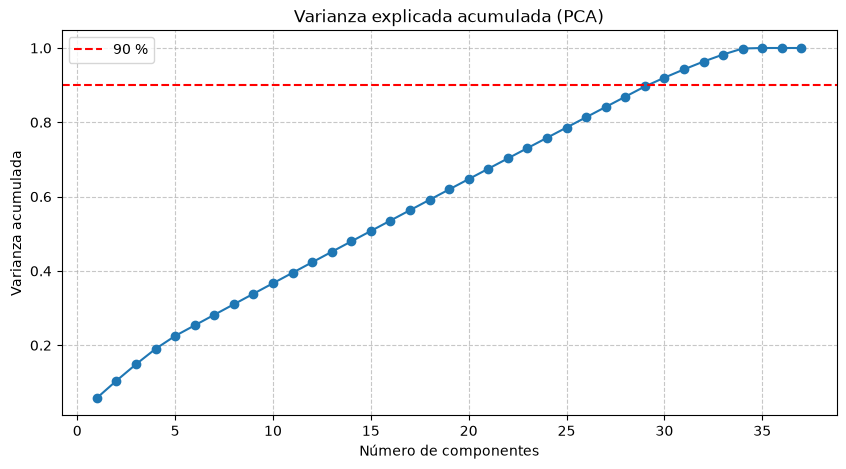

In [41]:
# Varianza explicada acumulada según el número de componentes
plt.figure(figsize=(10, 5))

plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o')
plt.axhline(0.9, color='red', linestyle='--', label='90 %')

plt.title('Varianza explicada acumulada (PCA)')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

plt.show()

In [42]:
# Número de componentes para llegar al 90 % de la varianza
n_componentes = int(np.argmax(varianza_acumulada >= 0.90)) + 1

print("Componentes para el 90 % de la varianza:", n_componentes, "de", X_train_scaled.shape[1])
print("Varianza explicada:", round(sum(pca.explained_variance_ratio_[:n_componentes]), 3))
print("Componentes para el 95 % de la varianza:", int(np.argmax(varianza_acumulada >= 0.95)) + 1)

Componentes para el 90 % de la varianza: 30 de 37
Varianza explicada: 0.92
Componentes para el 95 % de la varianza: 32


In [43]:
# PCA solo con las dos posiciones (las que tienen correlación de 0.94 entre sí)
X_posiciones = StandardScaler().fit_transform(X_train[['StartPosition', 'QualifyingPosition']])

pca_posiciones = PCA(n_components=2)
pca_posiciones.fit(X_posiciones)

print("Varianza explicada por cada componente:", pca_posiciones.explained_variance_ratio_.round(3))

Varianza explicada por cada componente: [0.97 0.03]


### Interpretación

- **Número de componentes:** con el criterio visto en clase (90 % de varianza acumulada) se necesitan **30 componentes de 37**, que explican el **92.0 %** de la varianza. Para el 95 % se necesitarían 32.
- **Por qué reduce tan poco:** casi todas las columnas son One-Hot de `Location`, y esas columnas casi no están correlacionadas entre sí; por eso cada componente explica poco (el primero solo el 5.8 %). La curva de la gráfica sube casi en línea recta.
- **Dónde sí hay redundancia:** si se aplica PCA solo a `StartPosition` y `QualifyingPosition`, el primer componente explica el 97 % de la varianza de las dos. La multicolinealidad está concentrada en esas dos columnas.
- **Por qué se prueba:** hay multicolinealidad (0.94) y pocas filas por columna (6.1). Las desventajas vistas en clase son que se pierde interpretabilidad (cada componente mezcla circuitos, clima y posiciones) y que depende del escalado.

El impacto de PCA en los modelos se mide en la Sección 4.3 comparando la validación cruzada con y sin PCA.

# 4. Modelado

## 4.1 Modelos candidatos

Se usan los mismos tres modelos de regresión del primer corte, para comparar un modelo lineal con dos modelos basados en árboles.

**1. Regresión Lineal.** Estima `FinishPosition` como una suma ponderada de las variables. Es simple, fácil de interpretar y encaja con la relación casi lineal entre salida y llegada. Puede dar valores fuera del rango de 1 a 20.

**2. Árbol de Decisión.** Divide los datos con preguntas sobre las variables (por ejemplo, "¿la posición de salida es menor que 5?") y puede capturar relaciones no lineales. Un árbol muy profundo puede memorizar los datos (overfitting), por eso se limita con `max_depth`.

**3. Random Forest.** Promedia muchos árboles, lo que suele dar resultados más estables que un solo árbol. Es menos interpretable y también hay que controlar su complejidad.

Primero se usan los parámetros del primer corte (`max_depth=5`, `n_estimators=100`, `random_state=42`) y en la Sección 4.4 se ajustan.

### Métricas

- **MAE (error absoluto medio):** cuántas posiciones se equivoca el modelo en promedio. Trata igual todos los errores. Menor es mejor.
- **MSE (error cuadrático medio):** promedio de los errores al cuadrado; castiga mucho los errores grandes y queda en "posiciones al cuadrado". Menor es mejor.
- **RMSE:** raíz del MSE; vuelve a quedar en posiciones y castiga más los errores grandes que el MAE. Menor es mejor.
- **R²:** proporción de la variación de `FinishPosition` que explica el modelo. Es 0 si el modelo no mejora a predecir el promedio y puede ser negativo. Más cercano a 1 es mejor.

La métrica principal es el MAE porque se entiende directo en posiciones.

In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Los tres modelos (mismos parámetros del primer corte)
modelo_lineal = LinearRegression()
modelo_arbol = DecisionTreeRegressor(max_depth=5, random_state=42)
modelo_bosque = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)

# Diccionario para recorrer los modelos con un ciclo for
modelos = {
    'Regresión Lineal': modelo_lineal,
    'Árbol de Decisión': modelo_arbol,
    'Random Forest': modelo_bosque
}

print("Modelos definidos:", list(modelos.keys()))

Modelos definidos: ['Regresión Lineal', 'Árbol de Decisión', 'Random Forest']


## 4.2 Validación cruzada (KFold de 5 partes)

Se divide el entrenamiento en 5 partes con `KFold(n_splits=5, shuffle=True, random_state=42)`. En cada vuelta, 4 partes entrenan y 1 valida; el resultado es el promedio de las 5 vueltas. El conjunto de prueba **no se usa aquí**. `cross_val_score` devuelve los errores en negativo, por eso se multiplican por −1. Cada modelo se evalúa sin PCA y con PCA (30 componentes).

In [45]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline

# 5 partes con mezcla aleatoria; random_state=42 permite repetir la división
validacion = KFold(n_splits=5, shuffle=True, random_state=42)

resultados_cv = []

for usar_pca in ['No', 'Sí']:
    for nombre, modelo in modelos.items():
        if usar_pca == 'No':
            # Pipeline: primero el One-Hot y luego el modelo
            pipeline = Pipeline([('preprocesamiento', preprocesamiento), ('modelo', modelo)])
        else:
            # Con PCA: One-Hot, escalado, reducción y luego el modelo
            pipeline = Pipeline([
                ('preprocesamiento', preprocesamiento),
                ('escalado', StandardScaler()),
                ('pca', PCA(n_components=n_componentes)),
                ('modelo', modelo)
            ])

        mae = -cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='neg_mean_absolute_error')
        mse = -cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='neg_mean_squared_error')
        rmse = -cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='neg_root_mean_squared_error')
        r2 = cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='r2')

        # Promedio de las 5 partes
        resultados_cv.append({'Modelo': nombre, 'PCA': usar_pca, 'MAE (CV)': mae.mean(),
                              'MSE (CV)': mse.mean(), 'RMSE (CV)': rmse.mean(), 'R² (CV)': r2.mean()})

tabla_cv = pd.DataFrame(resultados_cv).round(3)
tabla_cv

,Modelo,PCA,MAE (CV),MSE (CV),RMSE (CV),R² (CV)
0,Regresión Lineal,No,4.035,24.106,4.887,0.441
1,Árbol de Decisión,No,4.561,33.958,5.823,0.191
2,Random Forest,No,4.074,24.848,4.960,0.418
3,Regresión Lineal,Sí,4.113,24.920,4.959,0.424
4,Árbol de Decisión,Sí,4.851,41.645,6.397,0.014
5,Random Forest,Sí,4.227,25.895,5.064,0.399


Las dos referencias del primer corte se calculan con las mismas 5 partes para poder compararlas directamente con la tabla anterior.

In [46]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Las dos referencias simples con las mismas 5 partes (no aprenden nada, solo se calculan)
resultados_ref_cv = []

for nombre in ['Predecir el promedio (entrenamiento)', 'Usar StartPosition']:
    mae, mse, rmse, r2 = [], [], [], []

    for filas_train, filas_val in validacion.split(X_train):
        y_val = y_train.iloc[filas_val]

        if nombre == 'Usar StartPosition':
            prediccion = X_train['StartPosition'].iloc[filas_val]
        else:
            prediccion = np.full(len(y_val), y_train.iloc[filas_train].mean())

        mae.append(mean_absolute_error(y_val, prediccion))
        mse.append(mean_squared_error(y_val, prediccion))
        rmse.append(np.sqrt(mean_squared_error(y_val, prediccion)))
        r2.append(r2_score(y_val, prediccion))

    resultados_ref_cv.append({'Referencia': nombre, 'MAE (CV)': np.mean(mae), 'MSE (CV)': np.mean(mse),
                              'RMSE (CV)': np.mean(rmse), 'R² (CV)': np.mean(r2)})

tabla_ref_cv = pd.DataFrame(resultados_ref_cv).round(3)
tabla_ref_cv

,Referencia,MAE (CV),MSE (CV),RMSE (CV),R² (CV)
0,Predecir el promedio (entrenamiento),5.76,43.486,6.580,-0.012
1,Usar StartPosition,3.57,20.694,4.518,0.520


### Interpretación

- Sin PCA, la Regresión Lineal tiene el menor error (MAE 4.035, R² 0.441), seguida muy de cerca por el Random Forest (4.074). El Árbol de Decisión con `max_depth=5` es el peor (4.561, R² 0.191).
- Todos los modelos mejoran mucho a "Predecir el promedio" (MAE 5.760, R² −0.012).
- Pero **ninguno mejora a "Usar StartPosition"**, que tiene MAE 3.570 y R² 0.520 con las mismas 5 partes.

## 4.3 Impacto de PCA

In [47]:
# Impacto de PCA: MAE en validación cruzada con y sin reducción
impacto_pca = tabla_cv.pivot(index='Modelo', columns='PCA', values='MAE (CV)')
impacto_pca['Diferencia (Sí - No)'] = impacto_pca['Sí'] - impacto_pca['No']

impacto_pca.round(3)

PCA,No,Sí,Diferencia (Sí - No)
Modelo,,,
Random Forest,4.074,4.227,0.153
Regresión Lineal,4.035,4.113,0.078
Árbol de Decisión,4.561,4.851,0.290


### Interpretación

PCA **empeora a los tres modelos**: el MAE sube 0.078 posiciones en la Regresión Lineal, 0.153 en el Random Forest y 0.290 en el Árbol de Decisión. Con 30 de 37 componentes casi no se reduce nada, pero sí se mezclan las variables: la información de `StartPosition` (la más útil) queda repartida entre varios componentes y los árboles ya no pueden hacer preguntas directas sobre ella. Por eso los modelos finales se eligen **sin PCA**. Es un resultado útil: la reducción no siempre mejora el modelo, y aquí la multicolinealidad está solo en dos columnas.

## 4.4 Ajuste de parámetros (GridSearchCV)

En el primer corte los parámetros no se ajustaron y quedó como trabajo futuro. Aquí se prueba con `GridSearchCV` para el árbol y el bosque (sin PCA, porque PCA empeoró), usando las mismas 5 partes. Se prueban `max_depth` (profundidad), `min_samples_leaf` (mínimo de carreras por hoja) y, en el bosque, `n_estimators` (número de árboles).

In [48]:
from sklearn.model_selection import GridSearchCV

# Valores a probar (en el primer corte los parámetros se fijaron sin ajustar)
parametros = {
    'Árbol de Decisión': {'modelo__max_depth': [2, 3, 4, 5, 7, 10],
                          'modelo__min_samples_leaf': [1, 5, 10, 20]},
    'Random Forest': {'modelo__n_estimators': [100, 300],
                      'modelo__max_depth': [3, 5, 7],
                      'modelo__min_samples_leaf': [1, 5, 10]}
}

resultados_ajuste = []

for nombre, grilla in parametros.items():
    pipeline = Pipeline([('preprocesamiento', preprocesamiento), ('modelo', modelos[nombre])])

    # GridSearchCV prueba todas las combinaciones con las mismas 5 partes de la validación cruzada
    busqueda = GridSearchCV(pipeline, grilla, cv=validacion, scoring='neg_mean_absolute_error')
    busqueda.fit(X_train, y_train)
    print(nombre, "- mejores parámetros:", busqueda.best_params_)

    # Se agrega al diccionario el modelo con los mejores parámetros
    modelos[nombre + ' (ajustado)'] = busqueda.best_estimator_.named_steps['modelo']

    mae_antes = tabla_cv[(tabla_cv['Modelo'] == nombre) & (tabla_cv['PCA'] == 'No')]['MAE (CV)'].iloc[0]
    resultados_ajuste.append({'Modelo': nombre, 'Mejores parámetros': busqueda.best_params_,
                              'MAE (CV) primer corte': mae_antes, 'MAE (CV) ajustado': -busqueda.best_score_})

tabla_ajuste = pd.DataFrame(resultados_ajuste).round(3)
tabla_ajuste

Árbol de Decisión - mejores parámetros: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 20}


Random Forest - mejores parámetros: {'modelo__max_depth': 3, 'modelo__min_samples_leaf': 10, 'modelo__n_estimators': 100}


,Modelo,Mejores parámetros,MAE (CV) primer corte,MAE (CV) ajustado
0,Árbol de Decisión,"{'modelo__max_depth': 3, 'modelo__min_samples_...",4.561,3.847
1,Random Forest,"{'modelo__max_depth': 3, 'modelo__min_samples_...",4.074,3.842


In [49]:
# Validación cruzada de los modelos ajustados con las cuatro métricas (sin PCA)
for nombre in ['Árbol de Decisión (ajustado)', 'Random Forest (ajustado)']:
    pipeline = Pipeline([('preprocesamiento', preprocesamiento), ('modelo', modelos[nombre])])

    mae = -cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='neg_mean_absolute_error')
    mse = -cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='neg_mean_squared_error')
    rmse = -cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='neg_root_mean_squared_error')
    r2 = cross_val_score(pipeline, X_train, y_train, cv=validacion, scoring='r2')

    resultados_cv.append({'Modelo': nombre, 'PCA': 'No', 'MAE (CV)': mae.mean(),
                          'MSE (CV)': mse.mean(), 'RMSE (CV)': rmse.mean(), 'R² (CV)': r2.mean()})

tabla_cv = pd.DataFrame(resultados_cv).round(3)
tabla_cv

,Modelo,PCA,MAE (CV),MSE (CV),RMSE (CV),R² (CV)
0,Regresión Lineal,No,4.035,24.106,4.887,0.441
1,Árbol de Decisión,No,4.561,33.958,5.823,0.191
2,Random Forest,No,4.074,24.848,4.960,0.418
3,Regresión Lineal,Sí,4.113,24.920,4.959,0.424
4,Árbol de Decisión,Sí,4.851,41.645,6.397,0.014
5,Random Forest,Sí,4.227,25.895,5.064,0.399
6,Árbol de Decisión (ajustado),No,3.847,22.206,4.693,0.483
7,Random Forest (ajustado),No,3.842,22.213,4.685,0.482


### Interpretación

- El mejor árbol usa `max_depth=3` y `min_samples_leaf=20`, y el MAE (CV) baja de 4.561 a **3.847**.
- El mejor Random Forest usa `max_depth=3`, `min_samples_leaf=10` y `n_estimators=100`, y baja de 4.074 a **3.842**.
- Los dos ajustados quedan mejor que la Regresión Lineal (4.035): árboles más simples (menos profundos y con hojas más grandes) generalizan mejor con 224 carreras. Aun así, **siguen sin superar a "Usar StartPosition" (3.570)**.
- Como los parámetros se eligieron con las mismas 5 partes, su resultado en CV es un poco optimista.

## 4.5 Entrenamiento y evaluación final

Cada modelo del diccionario (los tres del primer corte y los dos ajustados) se entrena con el conjunto de entrenamiento y se evalúa en entrenamiento y en prueba, con y sin PCA. El conjunto de prueba se usa una sola vez.

In [50]:
resultados = []

# Se evalúan los cinco modelos del diccionario (tres del primer corte y dos ajustados), con y sin PCA
for usar_pca in ['No', 'Sí']:
    for nombre, modelo in modelos.items():
        if usar_pca == 'No':
            pipeline = Pipeline([('preprocesamiento', preprocesamiento), ('modelo', modelo)])
        else:
            pipeline = Pipeline([
                ('preprocesamiento', preprocesamiento),
                ('escalado', StandardScaler()),
                ('pca', PCA(n_components=n_componentes)),
                ('modelo', modelo)
            ])

        # Entrenar (el One-Hot, el escalado, el PCA y el modelo aprenden solo de X_train)
        pipeline.fit(X_train, y_train)

        # Predicciones sobre entrenamiento y prueba
        pred_train = pipeline.predict(X_train)
        pred_test = pipeline.predict(X_test)

        # RMSE = raíz cuadrada del error cuadrático medio
        resultados.append({
            'Modelo': nombre,
            'PCA': usar_pca,
            'MAE train': mean_absolute_error(y_train, pred_train),
            'MAE prueba': mean_absolute_error(y_test, pred_test),
            'MSE train': mean_squared_error(y_train, pred_train),
            'MSE prueba': mean_squared_error(y_test, pred_test),
            'RMSE train': np.sqrt(mean_squared_error(y_train, pred_train)),
            'RMSE prueba': np.sqrt(mean_squared_error(y_test, pred_test)),
            'R² train': r2_score(y_train, pred_train),
            'R² prueba': r2_score(y_test, pred_test)
        })

tabla_resultados = pd.DataFrame(resultados).round(3)
tabla_resultados

,Modelo,PCA,MAE train,MAE prueba,MSE train,MSE prueba,RMSE train,RMSE prueba,R² train,R² prueba
0,Regresión Lineal,No,3.441,3.544,17.507,19.516,4.184,4.418,0.596,0.334
1,Árbol de Decisión,No,2.904,3.567,14.109,23.843,3.756,4.883,0.674,0.186
2,Random Forest,No,2.899,3.237,11.843,16.731,3.441,4.090,0.727,0.429
3,Árbol de Decisión (ajustado),No,3.586,2.879,19.599,14.530,4.427,3.812,0.548,0.504
4,Random Forest (ajustado),No,3.513,3.010,18.456,15.451,4.296,3.931,0.574,0.473
5,Regresión Lineal,Sí,3.555,3.080,18.660,15.733,4.320,3.967,0.569,0.463
6,Árbol de Decisión,Sí,2.463,3.987,10.718,25.744,3.274,5.074,0.753,0.121
7,Random Forest,Sí,2.481,3.566,8.382,20.027,2.895,4.475,0.807,0.316
8,Árbol de Decisión (ajustado),Sí,3.640,3.295,19.372,19.450,4.401,4.410,0.553,0.336
9,Random Forest (ajustado),Sí,3.369,3.659,16.405,19.968,4.050,4.469,0.621,0.318


# 5. Resultados y despliegue

## 5.1 Referencias simples en prueba

In [51]:
# Predicciones de las dos referencias sobre el conjunto de prueba
referencias = {
    'Predecir el promedio (entrenamiento)': np.full(len(y_test), y_train.mean()),
    'Usar StartPosition': X_test['StartPosition']
}

resultados_ref = []

for nombre, prediccion in referencias.items():
    resultados_ref.append({
        'Referencia': nombre,
        'MAE prueba': mean_absolute_error(y_test, prediccion),
        'MSE prueba': mean_squared_error(y_test, prediccion),
        'RMSE prueba': np.sqrt(mean_squared_error(y_test, prediccion)),
        'R² prueba': r2_score(y_test, prediccion)
    })

tabla_referencias = pd.DataFrame(resultados_ref).round(3)
tabla_referencias

,Referencia,MAE prueba,MSE prueba,RMSE prueba,R² prueba
0,Predecir el promedio (entrenamiento),4.718,31.585,5.620,-0.078
1,Usar StartPosition,3.143,17.286,4.158,0.410


## 5.2 Detección de overfitting y underfitting

Hay overfitting cuando el modelo es mucho mejor en entrenamiento que en datos nuevos, y underfitting cuando es malo en los dos.

In [52]:
# Diferencia entre entrenamiento y prueba (valores grandes indicarían overfitting)
diferencias = pd.DataFrame({
    'Modelo': tabla_resultados['Modelo'],
    'PCA': tabla_resultados['PCA'],
    'MAE prueba - MAE train': tabla_resultados['MAE prueba'] - tabla_resultados['MAE train'],
    'R² train - R² prueba': tabla_resultados['R² train'] - tabla_resultados['R² prueba']
}).round(3)

diferencias

,Modelo,PCA,MAE prueba - MAE train,R² train - R² prueba
0,Regresión Lineal,No,0.103,0.262
1,Árbol de Decisión,No,0.663,0.488
2,Random Forest,No,0.338,0.298
3,Árbol de Decisión (ajustado),No,-0.707,0.044
4,Random Forest (ajustado),No,-0.503,0.101
5,Regresión Lineal,Sí,-0.475,0.106
6,Árbol de Decisión,Sí,1.524,0.632
7,Random Forest,Sí,1.085,0.491
8,Árbol de Decisión (ajustado),Sí,-0.345,0.217
9,Random Forest (ajustado),Sí,0.290,0.303


### Interpretación

- **Overfitting:** el Árbol de Decisión con `max_depth=5` tiene MAE de 2.904 en entrenamiento, 4.561 en validación cruzada y 3.567 en prueba; con PCA la diferencia en prueba llega a 1.524 posiciones. El Random Forest base también sobreajusta (2.899 en entrenamiento contra 4.074 en CV). Con PCA el overfitting de los árboles aumenta.
- **Modelos ajustados:** el árbol y el bosque ajustados tienen errores parecidos en entrenamiento (3.586 y 3.513) y en CV (3.847 y 3.842): ya no memorizan. Que en prueba les vaya mejor que en entrenamiento (diferencias negativas) se debe a que las 56 carreras de prueba son más fáciles: incluso "Usar StartPosition" baja de 3.570 en CV a 3.143 en prueba.
- **Underfitting:** "Predecir el promedio" es el caso extremo (R² negativo en CV y en prueba). La Regresión Lineal tiene un error de entrenamiento (3.441) cercano al de prueba (3.544) y R² de entrenamiento de 0.596: no sobreajusta, pero su forma lineal le impide bajar más el error (algo de underfitting).

## 5.3 Impacto de PCA en prueba

En prueba, PCA empeora a los árboles (por ejemplo, el árbol ajustado pasa de MAE 2.879 a 3.295 y el bosque ajustado de 3.010 a 3.659). La única excepción es la Regresión Lineal (3.544 → 3.080), pero en validación cruzada PCA también la empeora (4.035 → 4.113) y la prueba tiene solo 56 carreras. La conclusión de la Sección 4.3 se mantiene: no se usa PCA en el modelo final.

## 5.4 Selección del mejor modelo

El mejor modelo se elige con la **validación cruzada**, no con la prueba, porque la prueba es una sola división de 56 carreras.

In [53]:
# Modelo con mejor resultado en validación cruzada según cada métrica
print("Menor MAE en validación cruzada:", tabla_cv.loc[tabla_cv['MAE (CV)'].idxmin(), ['Modelo', 'PCA']].tolist())
print("Menor RMSE en validación cruzada:", tabla_cv.loc[tabla_cv['RMSE (CV)'].idxmin(), ['Modelo', 'PCA']].tolist())
print("Mayor R² en validación cruzada:", tabla_cv.loc[tabla_cv['R² (CV)'].idxmax(), ['Modelo', 'PCA']].tolist())

# Comparación con la referencia "Usar StartPosition" (mismas 5 partes)
mae_start_cv = tabla_ref_cv.loc[tabla_ref_cv['Referencia'] == 'Usar StartPosition', 'MAE (CV)'].iloc[0]
print("\nMenor MAE (CV) de un modelo:", tabla_cv['MAE (CV)'].min())
print("MAE (CV) de Usar StartPosition:", mae_start_cv)

Menor MAE en validación cruzada: ['Random Forest (ajustado)', 'No']
Menor RMSE en validación cruzada: ['Random Forest (ajustado)', 'No']
Mayor R² en validación cruzada: ['Árbol de Decisión (ajustado)', 'No']

Menor MAE (CV) de un modelo: 3.842
MAE (CV) de Usar StartPosition: 3.57


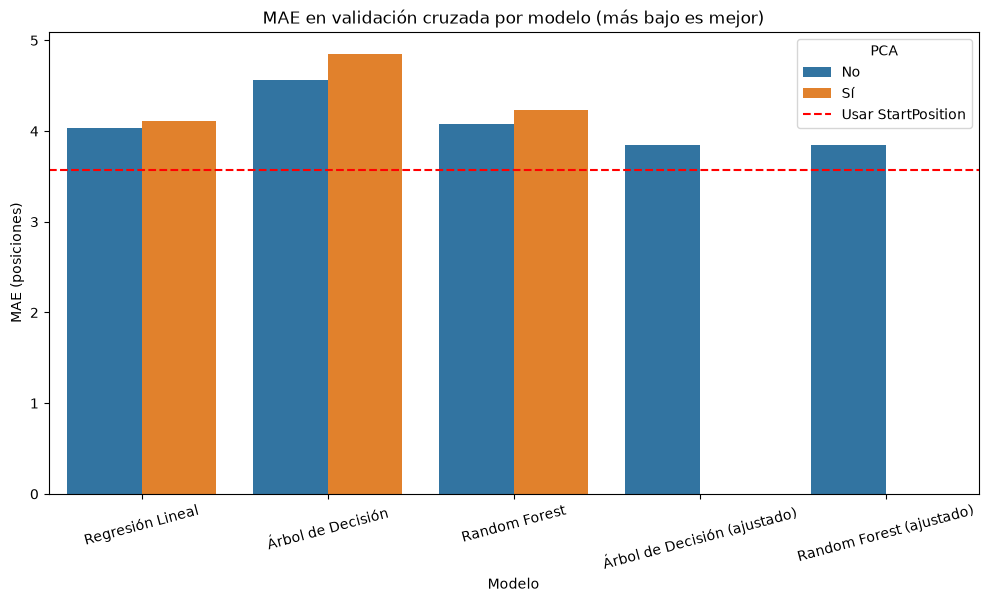

In [54]:
# MAE en validación cruzada de cada modelo, con y sin PCA
plt.figure(figsize=(12, 6))

sns.barplot(data=tabla_cv, x='Modelo', y='MAE (CV)', hue='PCA')
plt.axhline(mae_start_cv, color='red', linestyle='--', label='Usar StartPosition')

plt.title('MAE en validación cruzada por modelo (más bajo es mejor)')
plt.xlabel('Modelo')
plt.ylabel('MAE (posiciones)')
plt.xticks(rotation=15)
plt.legend(title='PCA')

plt.show()

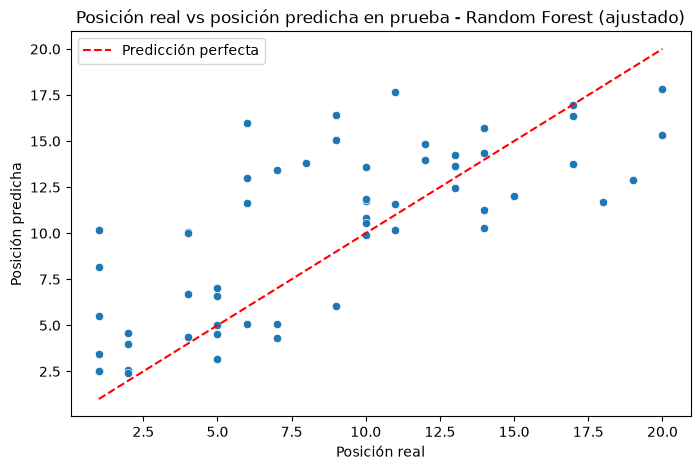

In [55]:
# Posición real vs posición predicha en prueba con el mejor modelo por CV (no usa PCA)
nombre_mejor = tabla_cv.loc[tabla_cv['MAE (CV)'].idxmin(), 'Modelo']
pipeline_final = Pipeline([('preprocesamiento', preprocesamiento), ('modelo', modelos[nombre_mejor])])
pipeline_final.fit(X_train, y_train)
pred_final = pipeline_final.predict(X_test)

plt.figure(figsize=(8, 5))

sns.scatterplot(x=y_test, y=pred_final)
plt.plot([1, 20], [1, 20], color='red', linestyle='--', label='Predicción perfecta')

plt.title('Posición real vs posición predicha en prueba - ' + nombre_mejor)
plt.xlabel('Posición real')
plt.ylabel('Posición predicha')
plt.legend()

plt.show()

### Lectura de los resultados

Estas observaciones corresponden a la ejecución con `random_state=42`.

- **Mejor modelo:** el **Random Forest ajustado** (`max_depth=3`, `min_samples_leaf=10`, `n_estimators=100`, sin PCA) tiene el menor MAE (3.842) y el menor RMSE (4.685) en validación cruzada. El árbol ajustado queda prácticamente empatado (MAE 3.847, R² 0.483 contra 0.482). Se elige el bosque porque promedia muchos árboles y es más estable que un solo árbol.
- **En prueba**, el Random Forest ajustado tiene MAE de 3.010, RMSE de 3.931 y R² de 0.473.
- **Frente a las referencias:** en validación cruzada **ningún modelo supera a "Usar StartPosition"** (MAE 3.570 contra 3.842 del mejor modelo). En prueba el bosque ajustado sí queda un poco mejor (3.010 contra 3.143), pero con 56 carreras esa diferencia no es confiable y la validación cruzada (5 particiones) dice lo contrario. La conclusión honesta es que, en este dataset, la posición de salida concentra casi toda la información útil y los modelos no la mejoran de forma consistente.
- **Gráfica real vs predicha:** los puntos siguen la diagonal (las salidas buenas terminan adelante), pero con mucha dispersión alrededor, que es el error de unas 3 posiciones que muestran las métricas.

## 5.5 Despliegue en Streamlit

La aplicación sigue la estructura vista en clase:

| Archivo | Función |
|---|---|
| `app.py` | Interfaz (frontend) con Streamlit: entradas del usuario, ejecución del modelo y gráficas |
| `model.py` | Lógica (backend): `load_data()`, `preprocessing(df)`, `train(...)`, `evaluate(...)` y `predict(...)` |
| `requirements.txt` | Librerías que necesita Streamlit Cloud para correr la app |
| `data/f1_enhanced_dataset_for_analysis.csv` | El dataset (va dentro del repositorio para que la app lo lea) |

**Cómo se conecta con el modelo:** `app.py` importa las funciones de `model.py`. Al abrir la app se cargan las 300 filas de Verstappen, `preprocessing` quita los 20 abandonos y deja las 5 predictoras, y se hace la misma división 80/20 con `random_state=42` que en este notebook. `train` arma el mismo `Pipeline` (`ColumnTransformer` con `OneHotEncoder(handle_unknown='ignore')` + modelo, y opcionalmente `StandardScaler` + `PCA`) y lo entrena en vivo con los parámetros que elige el usuario. Por eso, con los valores por defecto (Random Forest, `max_depth=3`, `min_samples_leaf=10`, `n_estimators=100`, sin PCA) la app muestra el mismo MAE en prueba que este notebook (3.010).

**Qué hace el usuario:**
1. Ve la vista previa del dataset.
2. Elige el modo de variables (selección manual o reducción con PCA y el número de componentes) y el modelo con sus parámetros (`max_depth`, `min_samples_leaf`, `n_estimators`).
3. Ingresa los datos de la carrera: año, circuito, clima, posición de clasificación y posición de salida.
4. Ve la posición final predicha (de 1 a 20), una gráfica de salida vs predicción, las métricas en prueba (MAE, MSE, RMSE y R²), la comparación con "Usar StartPosition" y la gráfica de posición real vs predicha.

- Enlace de la app: (pendiente)
- Repositorio en GitHub: (pendiente)

# 6. Conclusiones

**Datos.** Se partió de los 6.000 registros y 17 variables del primer corte y se tomaron las 300 carreras de Max Verstappen. No hubo nulos, duplicados, formatos inconsistentes, errores de digitación, tipos incorrectos ni outliers; solo se quitaron los 20 abandonos (300 → 280 filas). Verstappen tiene una posición promedio de 9.96, casi igual a la de los demás pilotos, lo que confirma que el dataset parece sintético.

**EDA.** `StartPosition` (0.73) y `QualifyingPosition` (0.70) son las variables con más relación con la posición final, y están correlacionadas en 0.94 entre sí. El clima, el circuito y el año no muestran un efecto claro.

**Data Leakage.** Se mantuvieron las exclusiones del primer corte (`Points`, `DNF`, `FastestLapTime_sec`, `PitStopCount`, `Overtakes`, `RaceTime_sec`, `TireStrategy`, `RaceID`, `RaceName`) y se agregaron `Driver` y `Team` por ser constantes.

**PCA.** Para el 90 % de la varianza se necesitan 30 de 37 componentes (92.0 %). PCA empeoró a los tres modelos en validación cruzada, así que el modelo final no lo usa.

**Modelos.** La Regresión Lineal fue el mejor modelo con los parámetros del primer corte (MAE CV 4.035). Al ajustar los parámetros, el Random Forest (`max_depth=3`, `min_samples_leaf=10`) bajó a 3.842 y es el modelo elegido. Los árboles sin ajustar sobreajustan; los ajustados no.

**Respuesta a la pregunta.** Con la información previa a la carrera, el mejor modelo predice la posición final de Verstappen con un error promedio de unas 3.8 posiciones en validación cruzada (3.0 en prueba). Sin embargo, en validación cruzada **no supera a la regla simple "Usar StartPosition"** (3.57): en este dataset, lo mejor que se puede decir antes de la carrera es, aproximadamente, que Verstappen termina cerca de donde sale.

# 7. Limitaciones y trabajo futuro

**Limitaciones.**
- El dataset parece sintético (Verstappen queda en el promedio de todos los pilotos y hay abandonos con posición 1), así que los resultados no se pueden llevar a la Fórmula 1 real.
- Solo hay 280 carreras: 224 para entrenar y 56 para probar. Con tan pocos datos, el resultado en prueba cambia mucho de un modelo a otro y puede contradecir a la validación cruzada (como pasó con "Usar StartPosition").
- Los parámetros se ajustaron con las mismas 5 partes con las que se comparan los modelos, por lo que su MAE en CV es un poco optimista.
- La regresión puede dar valores fuera de 1 a 20 (en la app se redondean y se limitan a ese rango) y no sabe que en una carrera real no puede haber dos pilotos en la misma posición.
- PCA no ayudó porque la mayoría de columnas son One-Hot de circuitos, que no tienen redundancia entre sí.

**Trabajo futuro.**
- Probar con datos reales de la F1 (por ejemplo, de la API pública de resultados) para ver si las conclusiones se mantienen.
- Predecir la diferencia entre la posición final y la de salida (`FinishPosition − StartPosition`), que es justo lo que la regla simple no explica.
- Usar validación cruzada anidada para ajustar los parámetros sin resultados optimistas.
- Plantear el problema como clasificación ordinal o como ranking de los 20 pilotos de una carrera.

# 8. Declaración de uso de IA

Según la guía de aprendizaje del curso (sección 9), se declara el uso de inteligencia artificial en este proyecto:

- **Herramienta:** Claude (Anthropic), usado a través de Claude Code.
- **Versión del modelo:** Claude Opus 5.5.
- **Para qué se usó:** planear la estructura del segundo corte a partir del enunciado del profesor; redactar y revisar código (limpieza, PCA, validación cruzada, ajuste de parámetros y la app de Streamlit); adaptar el código y los textos al estilo usado en clase y en el notebook del primer corte; y revisar que los números del texto coincidan con las salidas del código.
- **Prompts principales:** (completar: prompts principales usados)
- **Aportes del equipo:** la definición del problema y el análisis del primer corte (dataset, variables, tabla de Data Leakage, modelos y métricas propuestos), la elección del piloto y de la pregunta del segundo corte, y la revisión y validación de los resultados y de las conclusiones.